# Домашнее задание 3. Логистическая регрессия и Streamlit

## Описание

В этом задании вы реализуете логистическую регрессию своими руками, разберётесь с метриками качества классификации на реальных несбалансированных данных и упакуете итоговую модель в интерактивное веб-приложение на Streamlit.

- Первая часть посвящена реализации логистической регрессии с помощью градиентного и стохастического градиентного спуска.
- Вторая часть посвящена метрикам классификации: матрице ошибок, precision, recall, $F_\beta$, ROC- и PR-кривым, выбору порога.
- Третья часть посвящена работе с несбалансированными классами.
- Четвертая часть посвящена созданию демонстрации на Streamlit.

**Максимальный балл за задание: 10** (по 2.5 балла за каждую из четырёх частей).

## Общие требования к ДЗ-3

- Для каждого задания приведите код решения.
- Там, где требуется интерпретация, добавьте короткий текстовый вывод.
- Следите за тем, чтобы ноутбук выполнялся последовательно сверху вниз.
- Везде, где есть случайность, фиксируйте `random_state=42`.
- Тестовая выборка используется **только** для финальной оценки качества. Всё, что «подбирается» (гиперпараметры, порог, ресемплинг, параметры масштабирования), подбирается по тренировочной выборке.

> В каждой части оцениваются как код, так и ответы на вопросы. Если отсутствует одно из двух, часть баллов за соответствующее задание может быть снижена.

In [1]:
%pip install imbalanced-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.3.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn import metrics

sns.set_style('darkgrid')
RANDOM_STATE = 42

## <font color="green">Часть 1. Логистическая регрессия своими руками (2.5 балла)</font>

На лекции мы получили функцию потерь логистической регрессии из метода максимума правдоподобия. Если $p_i = \sigma(\langle w, x_i \rangle)$ – предсказанная вероятность класса 1 для $i$-го объекта, то

$$Q(w) = -\frac{1}{\ell}\sum_{i=1}^{\ell}\Big(y_i \log p_i + (1 - y_i)\log(1 - p_i)\Big) \to \min_w, \qquad \sigma(z) = \frac{1}{1 + e^{-z}}.$$

Явной формулы для минимума, как у МНК, здесь нет, поэтому веса ищем градиентным спуском – так же, как на семинаре 3 для линейной регрессии.

**Подсказка.** Сначала выведите градиент $\nabla Q(w)$ на бумаге и запишите его в матричном виде через $X$, $y$ и вектор вероятностей $p$. Вывод градиента приводить в ноутбуке не обязательно, но на защите его могут попросить.

### Задание 1.1. Класс `LogReg` (1.5 балла)

Реализуйте класс логистической регрессии, обучаемой с помощью:
- **полного градиентного спуска** – `gd_type='full'` (1 балл);
- **стохастического градиентного спуска** – `gd_type='stochastic'`: на каждой итерации градиент оценивается по случайному батчу из `batch_size` объектов, как в функции `calc_grad_on_batch` с семинара 3 (0.5 балла).

**Требования:**
- Градиентный спуск записан в векторном виде. Циклы средствами Python допускаются **только** по итерациям градиентного спуска.
- Свободный член $w_0$ учитывается так, как на лекции: внутри `fit` и `predict_proba` к матрице признаков добавляется фиктивный признак $x_0 = 1$ (первым столбцом). Таким образом, `self.w` имеет размер `d + 1`, и `self.w[0]` – это свободный член.
- Критерии остановки (одновременно):
  - L2 норма разности весов на двух соседних итерациях меньше `tolerance`;
  - достигнуто максимальное число итераций `max_iter`.
- Атрибут `loss_history` после вызова `fit` содержит значение функции потерь **на всей обучающей выборке** для каждой итерации, начиная с первой (до совершения первого шага по антиградиенту).
- Веса инициализируются вектором `w0`, если он передан, иначе – нулевым вектором.
- `predict_proba` возвращает массив размера `(N, 2)`: в первом столбце вероятность класса 0, во втором – класса 1 (как в `sklearn`).
- `predict` возвращает метки классов `0/1`, сравнивая вероятность класса 1 с порогом `threshold`.
- При вычислении логарифма в `calc_loss` позаботьтесь о вычислительной устойчивости: $\log 0$ давать не должно (например, используйте `np.clip`).

Полезно [почитать](https://scikit-learn.org/stable/developers/develop.html) о том, как устроены модели в `sklearn`.

**ВАЖНО!** Заполните шаблон ниже, не меняя структуру класса и сигнатуры методов. Добавлять свои вспомогательные методы можно.

In [3]:
class LogReg(BaseEstimator, ClassifierMixin):
    def __init__(self, gd_type='full', tolerance=1e-4, max_iter=1000,
                 w0=None, eta=1e-2, batch_size=32, random_state=42):
        """
        gd_type: 'full' или 'stochastic'
        tolerance: порог для критерия останова по норме разности весов
        max_iter: максимальное число итераций градиентного спуска
        w0: np.array размера (d + 1) — начальные веса (w0[0] — свободный член)
        eta: длина шага (learning rate)
        batch_size: размер батча для стохастического градиентного спуска
        random_state: seed для выбора батчей
        """
        self.gd_type = gd_type
        self.tolerance = tolerance
        self.max_iter = max_iter
        self.w0 = w0
        self.eta = eta
        self.batch_size = batch_size
        self.random_state = random_state

    def fit(self, X, y):
        """
        X: np.array размера (N, d)
        y: np.array размера (N) из 0 и 1
        ---
        output: self
        """
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        self.classes_ = np.array([0, 1])
        self.loss_history = []
        rng = np.random.default_rng(self.random_state)
        X = np.hstack([np.ones((X.shape[0], 1)), X])
        if self.w0 is not None:
            self.w = np.copy(np.asarray(self.w0, dtype=float))
        else:
            self.w = np.zeros(X.shape[1], dtype=float)

        for i in range(self.max_iter):
            loss = self.calc_loss(X, y)
            self.loss_history.append(loss)
            if self.gd_type == 'full':
                gradient = self.calc_gradient(X, y)
                old_w = np.copy(self.w)
                self.w -= self.eta * gradient
                if np.linalg.norm(old_w - self.w) < self.tolerance:
                    break
            elif self.gd_type == 'stochastic':
                ind = rng.choice(X.shape[0], size=self.batch_size, replace=False)
                X_batch = X[ind]
                y_batch = y[ind]
                gradient = self.calc_gradient(X_batch, y_batch)
                old_w = np.copy(self.w)
                self.w -= self.eta * gradient
                if np.linalg.norm(old_w - self.w) < self.tolerance:
                    break
        return self

    def sigmoid(self, z):
        sigmoid = 1 / (1 + np.exp(-z))
        return sigmoid

    def predict_proba(self, X):
        """
        X: np.array размера (N, d)
        ---
        output: np.array размера (N, 2)
        """
        if getattr(self, 'w', None) is None:
            raise Exception('Not trained yet')

        X = np.asarray(X, dtype=float)
        X = np.hstack([np.ones((X.shape[0], 1)), X])
        p = self.sigmoid(X @ self.w)
        return np.vstack([1 - p, p]).T

    def predict(self, X, threshold=0.5):
        """
        X: np.array размера (N, d)
        ---
        output: np.array размера (N) из 0 и 1
        """
        if getattr(self, 'w', None) is None:
            raise Exception('Not trained yet')

        p = self.predict_proba(X)[:, 1]
        return (p >= threshold).astype(int)


    def calc_gradient(self, X, y):
        """
        X: np.array размера (N, d + 1) — уже с фиктивным признаком
           (N может быть равно batch_size при стохастическом спуске)
        y: np.array размера (N)
        ---
        output: np.array размера (d + 1) — градиент log-loss по self.w
        """
        z = X @ self.w
        sigmoid = self.sigmoid(z)
        gradient = sigmoid - y
        gradient = X.T @ gradient / X.shape[0]
        return gradient

    def calc_loss(self, X, y):
        """
        X: np.array размера (N, d + 1) — уже с фиктивным признаком
        y: np.array размера (N)
        ---
        output: float — значение log-loss при текущих self.w
        """
        z = X @ self.w
        sigmoid = np.clip(self.sigmoid(z), 1e-15, 1 - 1e-15)
        loss = -np.mean(y * np.log(sigmoid) + (1 - y) * np.log(1 - sigmoid))

        return loss

Ячейка ниже проверяет вашу реализацию градиента численно: сравнивает `calc_gradient` с конечными разностями функции `calc_loss`. Она не оценивается, но если проверка не проходит – ищите ошибку, прежде чем идти дальше.

In [4]:
def check_gradient(model, d=5, N=50, eps=1e-6, seed=0):
    rng = np.random.default_rng(seed)
    X = np.hstack([np.ones((N, 1)), rng.normal(size=(N, d))])
    y = rng.integers(0, 2, size=N).astype(float)
    model.w = rng.normal(size=d + 1)

    analytic = model.calc_gradient(X, y)
    numeric = np.zeros(d + 1)
    w = model.w.copy()
    for j in range(d + 1):
        e = np.zeros(d + 1)
        e[j] = eps
        model.w = w + e
        loss_plus = model.calc_loss(X, y)
        model.w = w - e
        loss_minus = model.calc_loss(X, y)
        numeric[j] = (loss_plus - loss_minus) / (2 * eps)
    model.w = w
    return np.max(np.abs(analytic - numeric))


err = check_gradient(LogReg())
print(f'max |analytic - numeric| = {err:.2e}')
assert err < 1e-5, 'Градиент не совпадает с численным — проверьте calc_gradient и calc_loss'

max |analytic - numeric| = 1.44e-10


Теперь проверим работу класса на синтетических данных.

In [5]:
X, y = make_classification(
    n_samples=20000, n_features=20, n_informative=5,
    random_state=RANDOM_STATE)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE)

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

### Задание 1.2. Обучение и сходимость (0.25 балла)

1. Обучите две модели: `LogReg(gd_type='full')` и `LogReg(gd_type='stochastic')` с параметрами по умолчанию.
2. Для каждой модели выведите число сделанных итераций и постройте на одном графике `loss_history` обеих моделей.
3. Ответьте на вопросы:
   - По какому критерию остановилась каждая модель – по `tolerance` или по `max_iter`?
   - Почему стохастическому спуску с постоянным шагом трудно остановиться по критерию `tolerance`?
   - Чем отличаются графики функции потерь?
   - Сколько объектов «просматривает» за одну итерацию каждый из методов?

In [6]:
model_full = LogReg(gd_type='full')
model_stochastic = LogReg(gd_type='stochastic')

model_full.fit(X_train, y_train)
model_stochastic.fit(X_train, y_train)

,gd_type,'stochastic'
,tolerance,0.0001
,max_iter,1000
,w0,None
,eta,0.01
,batch_size,32
,random_state,42
Name,Type,Value
classes_,"ndarray[int64](2,)","[0,1]"


In [7]:
display(len(model_full.loss_history))
display(len(model_stochastic.loss_history))

1000

1000

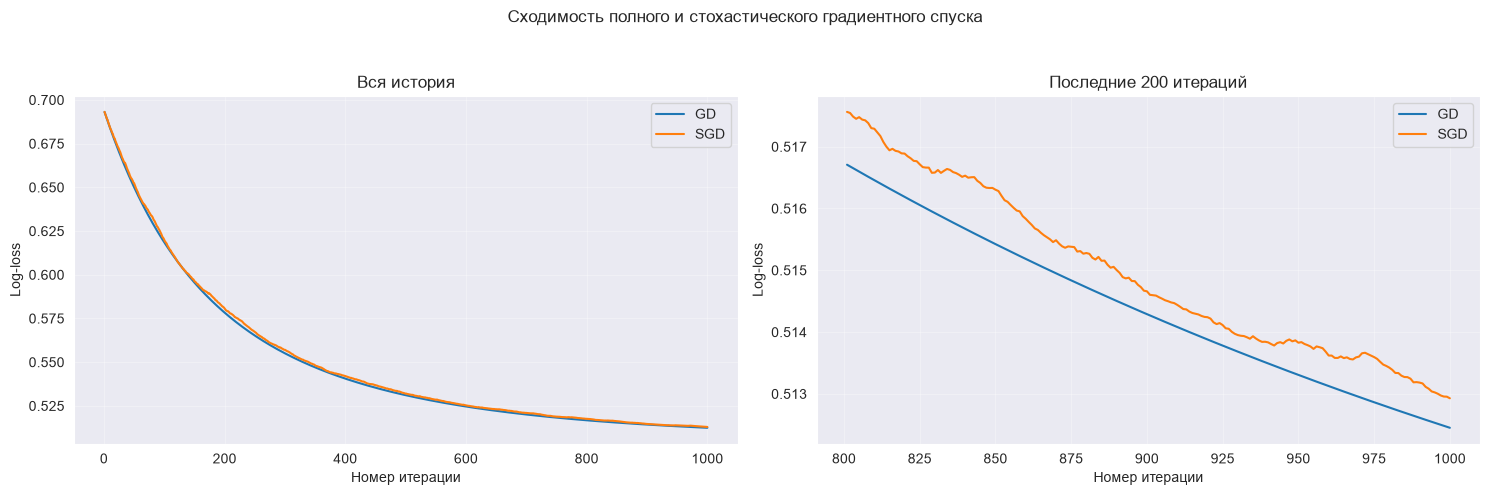

In [8]:
#этот код был написал с помощью ChatGPT-6.1 Sol

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle('Сходимость полного и стохастического градиентного спуска')

iterations_full = np.arange(1, len(model_full.loss_history) + 1)
iterations_stochastic = np.arange(1, len(model_stochastic.loss_history) + 1)

axes[0].plot(iterations_full, model_full.loss_history, label='GD')
axes[0].plot(iterations_stochastic, model_stochastic.loss_history, label='SGD')
axes[0].set_title('Вся история')

zoom_steps = 200
axes[1].plot(
    iterations_full[-zoom_steps:],
    model_full.loss_history[-zoom_steps:],
    label='GD'
)
axes[1].plot(
    iterations_stochastic[-zoom_steps:],
    model_stochastic.loss_history[-zoom_steps:],
    label='SGD'
)
axes[1].set_title(f'Последние {zoom_steps} итераций')

for ax in axes:
    ax.set_xlabel('Номер итерации')
    ax.set_ylabel('Log-loss')
    ax.legend()
    ax.grid(alpha=0.3)

fig.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()


*Ваши выводы здесь.*

Обе по max_iter

Потому что случайный батч дает немного разный градиент каждый раз так что даже около минимума веса продолжают колебаться

График полного спуска гладкий и постоянно уменьшается, а стохастическая "скачет" и уменьшается в целом но неравномерно

Полный спуск просматривает все объекты, стохастический - только батч (32 в нашем случае), при этом лосс считается по всей выборке в обоих случаях

### Задание 1.3. Длина шага (0.25 балла)

Для полного градиентного спуска обучите модели с сеткой `eta` из списка `[1e-3, 1e-2, 1e-1, 1, 10]` и постройте графики `loss_history` (удобно в логарифмической шкале по оси `x`). Выведите для каждого `eta` финальное значение функции потерь и число итераций.

Как длина шага влияет на скорость и качество сходимости? Есть ли значения `eta`, при которых спуск ведёт себя плохо?

In [9]:
etas = [1e-3, 1e-2, 1e-1, 1, 10]
models = dict()
for eta in etas:
    model = LogReg(eta=eta)
    model.fit(X_train, y_train)
    models[eta] = model

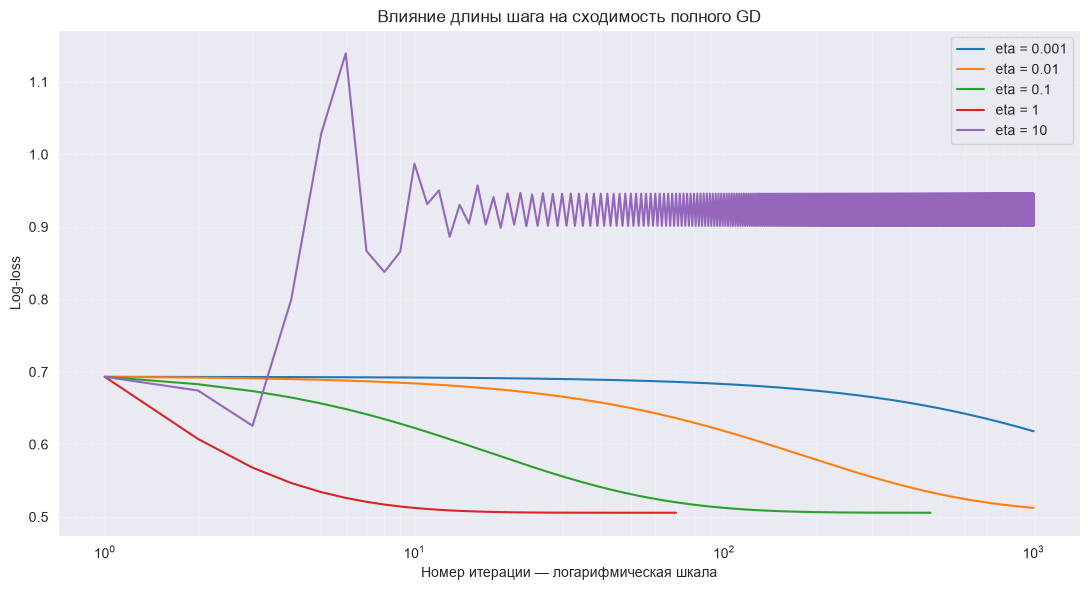

In [10]:
# этот код написан с помощью ChatGPT-6.1 Sol
plt.figure(figsize=(11, 6))

for eta, model in models.items():
    iterations = np.arange(1, len(model.loss_history) + 1)
    plt.plot(iterations, model.loss_history, label=f'eta = {eta}')

plt.xscale('log')
plt.xlabel('Номер итерации — логарифмическая шкала')
plt.ylabel('Log-loss')
plt.title('Влияние длины шага на сходимость полного GD')
plt.legend()
plt.grid(which='both', alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
for eta, model in models.items():
    iterations = len(model.loss_history)
    final_loss = metrics.log_loss(y_train, model.predict_proba(X_train))
    print(f'eta = {eta}: {iterations} итераций, loss = {final_loss:.4f}')

eta = 0.001: 1000 итераций, loss = 0.6181
eta = 0.01: 1000 итераций, loss = 0.5124
eta = 0.1: 465 итераций, loss = 0.5058
eta = 1: 70 итераций, loss = 0.5058
eta = 10: 1000 итераций, loss = 0.9013


*Ваши выводы здесь.*
Как длина шага влияет на скорость и качество сходимости? Есть ли значения `eta`, при которых спуск ведёт себя плохо?

Чем больше шаг (в устойчивом диапозоне) тем быстрее спуск, но при слишком большом шаге мы рискуем "перепрыгнуть" через минимум и не сойтись (как в примере с eta = 10)

Да, при eta = 10 спуск ведет себя плохо, так как мы перепрыгиваем через минимум и градиентный спуск не сходится, а колеблется вокруг 0.9 при минимуме в 0.5 и при eta = 0.001 спуск сходится настолько медленно, что останавливается на max_iter, не достигнув минимума даже близко

### Задание 1.4. Сравнение с `sklearn` (0.5 балла)

1. Обучите `LogisticRegression` из `sklearn` с параметрами по умолчанию.
2. Для трёх моделей (ваш GD, ваш SGD, `sklearn`) посчитайте на тестовой выборке accuracy и ROC-AUC и сведите их в таблицу `pd.DataFrame`.
3. Сравните веса вашей модели (GD) с весами модели `sklearn` (`intercept_` и `coef_`).

Ответьте на вопросы:
   - Совпадают ли метрики? Совпадают ли веса?
   - Что в модели `sklearn` по умолчанию делает её не равной вашей? Найдите ответ в [документации](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html). Как настроить `LogisticRegression`, чтобы она решала ту же задачу оптимизации, что и ваша модель?

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score

In [13]:
model_sklearn = LogisticRegression()
model_sklearn.fit(X_train, y_train)

model_full.predict(X_test)
model_stochastic.predict(X_test)
model_sklearn.predict(X_test)

full_accuracy = accuracy_score(y_test, model_full.predict(X_test))
stochastic_accuracy = accuracy_score(y_test, model_stochastic.predict(X_test))
sklearn_accuracy = accuracy_score(y_test, model_sklearn.predict(X_test))

full_roc_auc = roc_auc_score(y_test, model_full.predict_proba(X_test)[:, 1])
stochastic_roc_auc = roc_auc_score(y_test, model_stochastic.predict_proba(X_test)[:, 1])
sklearn_roc_auc = roc_auc_score(y_test, model_sklearn.predict_proba(X_test)[:, 1])

print(f'Full GD: Accuracy = {full_accuracy:.4f}, ROC AUC = {full_roc_auc:.4f}')
print(f'Stochastic GD: Accuracy = {stochastic_accuracy:.4f}, ROC AUC = {stochastic_roc_auc:.4f}')
print(f'Sklearn Logistic Regression: Accuracy = {sklearn_accuracy:.4f}, ROC AUC = {sklearn_roc_auc:.4f}')

metrics_pd = pd.DataFrame({
    'Model': ['Full GD', 'Stochastic GD', 'Sklearn Logistic Regression'],
    'Accuracy': [full_accuracy, stochastic_accuracy, sklearn_accuracy],
    'ROC AUC': [full_roc_auc, stochastic_roc_auc, sklearn_roc_auc]
})

display(metrics_pd)

Full GD: Accuracy = 0.7820, ROC AUC = 0.8388
Stochastic GD: Accuracy = 0.7825, ROC AUC = 0.8381
Sklearn Logistic Regression: Accuracy = 0.7765, ROC AUC = 0.8387


,Model,Accuracy,ROC AUC
0,Full GD,0.7820,0.838787
1,Stochastic GD,0.7825,0.838115
2,Sklearn Logistic Regression,0.7765,0.838676


In [14]:
w_full = model_full.w
w_sklearn = np.hstack([model_sklearn.intercept_, model_sklearn.coef_.flatten()])

display(pd.DataFrame({
    'Full GD': w_full,
    'Sklearn Logistic Regression': w_sklearn
}))


,Full GD,Sklearn Logistic Regression
0,-0.002114,-0.021880
1,0.006076,0.002741
2,0.006963,0.009039
3,-0.547170,-0.722690
4,-0.144536,-0.262335
5,0.012487,0.016588
6,-0.006325,-0.011488
7,0.000814,0.005587
8,0.039084,0.057188
9,-0.002425,-0.001239


*Ваши выводы здесь.*

Ответьте на вопросы:
   - Совпадают ли метрики? Совпадают ли веса?
   - Что в модели `sklearn` по умолчанию делает её не равной вашей? Найдите ответ в [документации](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html). Как настроить `LogisticRegression`, чтобы она решала ту же задачу оптимизации, что и ваша модель?
  
Практически совпадают, но не полностью. Веса различаются так как в sklearn по умолчанию используется L2 регуляризация + самописная модель остановилась по max_iter.

Как раз L2 регуляризация. Задать параметр C = np.inf что бы отключить регуляризацию


## <font color="green">Часть 2. Метрики классификации (2.5 балла)</font>

### Данные

Используем датасет [Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality) (P. Cortez et al., 2009, лицензия CC BY 4.0).
Каждая строка – образец португальского вина: 11 физико-химических характеристик и признак `is_red` (1 - красное, 0 - белое). Эксперты оценили каждое вино по шкале от 0 до 10. Мы превратили оценку в бинарную целевую переменную:

- `target = 1` – «хорошее» вино (оценка не ниже 7);
- `target = 0` – все остальные.

**Сценарий.** Сервис по подписке каждый месяц рекомендует клиентам вина. Модель должна по результатам лабораторного анализа отбирать «хорошие» вина в подборку. Рекомендовать клиенту посредственное вино — плохо (клиент разочаруется), но и пропускать хорошие вина тоже не хочется (подборка получится скудной).

In [15]:
df = pd.read_csv('https://raw.githubusercontent.com/paiflare/ml_hse_2026/refs/heads/master/homework/hw_3/Data/wine_quality.csv')

print('Data shape:', df.shape)
df.head()

Data shape: (6497, 13)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,is_red,target
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,1,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,1,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,1,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,1,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,1,0


In [16]:
X = df.drop(columns='target')
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)

print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (4547, 12)  Test: (1950, 12)


In [17]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed_acidity         6497 non-null   float64
 1   volatile_acidity      6497 non-null   float64
 2   citric_acid           6497 non-null   float64
 3   residual_sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free_sulfur_dioxide   6497 non-null   float64
 6   total_sulfur_dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  is_red                6497 non-null   int64  
 12  target                6497 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 660.0 KB


In [18]:
df.describe()

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,is_red,target
count,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000
mean,7.215307,0.339666,0.318633,5.443235,0.056034,30.525319,115.744574,0.994697,3.218501,0.531268,10.491801,0.246114,0.196552
std,1.296434,0.164636,0.145318,4.757804,0.035034,17.749400,56.521855,0.002999,0.160787,0.148806,1.192712,0.430779,0.397421
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000,0.000000,0.000000
25%,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000,0.000000,0.000000
50%,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,10.300000,0.000000,0.000000
75%,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,11.300000,0.000000,0.000000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000,1.000000,1.000000


In [19]:
df.sample(5, random_state=RANDOM_STATE)

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,is_red,target
3103,7.0,0.17,0.74,12.8,0.045,24.0,126.0,0.99420,3.26,0.38,12.2,0,1
1419,7.7,0.64,0.21,2.2,0.077,32.0,133.0,0.99560,3.27,0.45,9.9,1,0
4761,6.8,0.39,0.34,7.4,0.020,38.0,133.0,0.99212,3.18,0.44,12.0,0,1
4690,6.3,0.28,0.47,11.2,0.040,61.0,183.0,0.99592,3.12,0.51,9.5,0,0
4032,7.4,0.35,0.20,13.9,0.054,63.0,229.0,0.99888,3.11,0.50,8.9,0,0


### Задание 2.1. Первичный анализ и accuracy (0.25 балла)

1. Проверьте данные на пропуски и полные дубликаты строк. Нужно ли удалять дубликаты в этой задаче? Посчитайте долю класса 1 (prevalence) в тренировочной и тестовой выборках. Зачем при разбиении был указан параметр `stratify=y`?
2. Посчитайте accuracy на тестовой выборке для константной модели, которая всегда отвечает «не хорошее вино» (класс 0).
3. Обучите пайплайн `make_pipeline(StandardScaler(), LogisticRegression())` и посчитайте его accuracy на тестовой выборке.

Сравните два числа. Почему accuracy плохо подходит для этой задачи?

In [20]:
display(df.isna().sum())
display(df.isnull().sum())

fixed_acidity           0
volatile_acidity        0
citric_acid             0
residual_sugar          0
chlorides               0
free_sulfur_dioxide     0
total_sulfur_dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
is_red                  0
target                  0
dtype: int64

fixed_acidity           0
volatile_acidity        0
citric_acid             0
residual_sugar          0
chlorides               0
free_sulfur_dioxide     0
total_sulfur_dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
is_red                  0
target                  0
dtype: int64

In [21]:
df.duplicated().sum()

np.int64(1177)

In [22]:
ones = df['target'].sum() / len(df)
print(f'Proportion of positive class (1): {ones:.4f}')

ones_train = y_train.sum() / len(y_train)
ones_test = y_test.sum() / len(y_test)
print(f'Proportion of positive class (1) in train: {ones_train:.4f}')
print(f'Proportion of positive class (1) in test: {ones_test:.4f}')

Proportion of positive class (1): 0.1966
Proportion of positive class (1) in train: 0.1966
Proportion of positive class (1) in test: 0.1964


In [23]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

model_dummy = DummyClassifier(strategy='most_frequent')

model_dummy.fit(X_train, y_train)

dummy_pred = model_dummy.predict(X_test)

dummy_accuracy = accuracy_score(y_test, dummy_pred)

print(f'Dummy Classifier Accuracy: {dummy_accuracy:.4f}')

Dummy Classifier Accuracy: 0.8036


In [24]:
from sklearn.pipeline import make_pipeline

pipeline = make_pipeline(
    StandardScaler(),
    LogisticRegression()
)

model_pipeline = pipeline.fit(X_train, y_train)
pipeline_pred = model_pipeline.predict(X_test)

pipeline_accuracy = accuracy_score(y_test, pipeline_pred)

print(f'Pipeline Logistic Regression Accuracy: {pipeline_accuracy:.4f}')

Pipeline Logistic Regression Accuracy: 0.8200


*Ваши выводы здесь.*
Нужно ли удалять дубликаты в этой задаче? Думаю что нет, так как у разных вин могут быть одинаковые показатели.

Зачем при разбиении был указан параметр `stratify=y`? Потому что у нас несбалансированные классы (target = 0 примерно в 80% обьектов) и мы хотим сохранить пропорцию классов в тренировочной и тестовой выборках

Сравните два числа. Почему accuracy плохо подходит для этой задачи?
Dummy Classifier Accuracy: 0.8036
Pipeline Logistic Regression Accuracy: 0.8200

Плохо подходит так же из за несбалансированности классов, из за которой accuracy может быть высоким даже при плохой модели, которая не умеет выявлять редкий класс (класс 1).

### Задание 2.2. Матрица ошибок своими руками (0.5 балла)

Для пайплайна логистической регрессии из задания 2.1 получите предсказания классов на тестовой выборке.

1. Посчитайте TP, TN, FP, FN **без функций из `sklearn.metrics`** – только средствами `numpy`/`pandas`.
2. Сравните результат с `metrics.confusion_matrix` и нарисуйте матрицу ошибок с помощью `metrics.ConfusionMatrixDisplay`.
3. Объясните в терминах сценария, что означают FP и FN в этой задаче. Какая из ошибок модели встречается чаще?

In [25]:
TP = np.sum((pipeline_pred == 1) & (y_test == 1))
print(f'True Positives (TP): {TP}')
TN = np.sum((pipeline_pred == 0) & (y_test == 0))
print(f'True Negatives (TN): {TN}')
FP = np.sum((pipeline_pred == 1) & (y_test == 0))
print(f'False Positives (FP): {FP}')
FN = np.sum((pipeline_pred == 0) & (y_test == 1))
print(f'False Negatives (FN): {FN}')



True Positives (TP): 98
True Negatives (TN): 1501
False Positives (FP): 66
False Negatives (FN): 285


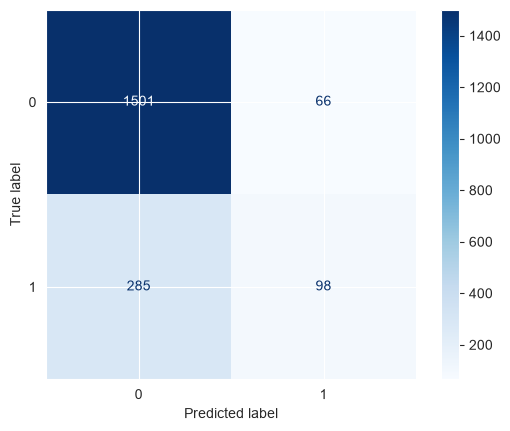

In [26]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, pipeline_pred)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model_pipeline.classes_).plot(cmap='Blues')

*Ваши выводы здесь.*
Объясните в терминах сценария, что означают FP и FN в этой задаче. Какая из ошибок модели встречается чаще?

FP - плохие вина попавшие в подборку, FN - хорошие вина не попавшие в подборку.

Чаще встречается FN так как у нас несбалансированные классы и модель чаще ошибается в сторону класса 0, так как он встречается чаще (модель чаще пропускает хорошие вина, чем ошибочно включает плохие вина в подборку)


### Задание 2.3. Precision, recall, $F_\beta$ (0.5 балла)

1. Используя TP, TN, FP, FN из задания 2.2, посчитайте по формулам precision, recall, $F_1$, $F_{0.5}$ и $F_2$:

$$F_{\beta} = (1 + \beta^2)\frac{\text{Precision} \cdot \text{Recall}}{\beta^2 \cdot \text{Precision} + \text{Recall}}.$$

2. Проверьте свои значения с помощью `metrics.precision_score`, `metrics.recall_score`, `metrics.fbeta_score`.
3. Ответьте на вопросы:
   - Что больше ценится в $F_{0.5}$, а что в $F_2$ – precision или recall?
   - Какую из трёх F-мер вы бы выбрали для нашего сценария, если подписчики очень болезненно реагируют на посредственные вина в подборке? А если сервис позиционирует себя как «самая широкая подборка хороших вин»?

In [27]:
precision = TP / (TP + FP) if (TP + FP) > 0 else 0
recall = TP / (TP + FN) if (TP + FN) > 0 else 0
F1_score = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
F05_score = (1 + 0.5**2) * (precision * recall) / ((0.5**2) * precision + recall) if ((0.5**2) * precision + recall) > 0 else 0
F2_score = (1 + 2**2) * (precision * recall) / ((2**2) * precision + recall) if ((2**2) * precision + recall) > 0 else 0

print(f'Precision: {precision:.4f}')
print(f'Recall: {recall:.4f}')
print(f'F1 Score: {F1_score:.4f}')
print(f'F0.5 Score: {F05_score:.4f}')
print(f'F2 Score: {F2_score:.4f}')


Precision: 0.5976
Recall: 0.2559
F1 Score: 0.3583
F0.5 Score: 0.4716
F2 Score: 0.2889


In [28]:
from sklearn.metrics import precision_score, recall_score, fbeta_score

presision_sklearn = precision_score(y_test, pipeline_pred)
recall_sklearn = recall_score(y_test, pipeline_pred)
F1_sklearn = fbeta_score(y_test, pipeline_pred, beta=1)
F05_sklearn = fbeta_score(y_test, pipeline_pred, beta=0.5)
F2_sklearn = fbeta_score(y_test, pipeline_pred, beta=2)

print(f'Sklearn Precision: {presision_sklearn:.4f}')
print(f'Sklearn Recall: {recall_sklearn:.4f}')
print(f'Sklearn F1 Score: {F1_sklearn:.4f}')
print(f'Sklearn F0.5 Score: {F05_sklearn:.4f}')
print(f'Sklearn F2 Score: {F2_sklearn:.4f}')
print(f'Precision match: {np.isclose(precision, presision_sklearn)}')
print(f'Recall match: {np.isclose(recall, recall_sklearn)}')
print(f'F1 match: {np.isclose(F1_score, F1_sklearn)}')
print(f'F0.5 match: {np.isclose(F05_score, F05_sklearn)}')
print(f'F2 match: {np.isclose(F2_score, F2_sklearn)}')

Sklearn Precision: 0.5976
Sklearn Recall: 0.2559
Sklearn F1 Score: 0.3583
Sklearn F0.5 Score: 0.4716
Sklearn F2 Score: 0.2889
Precision match: True
Recall match: True
F1 match: True
F0.5 match: True
F2 match: True


*Ваши выводы здесь.*

Что больше ценится в $F_{0.5}$, а что в $F_2$ – precision или recall?

В F0.5 больше ценится precision, так как beta < 1, а в F2 больше ценится recall, так как beta > 1

Какую из трёх F-мер вы бы выбрали для нашего сценария, если подписчики очень болезненно реагируют на посредственные вина в подборке? А если сервис позиционирует себя как «самая широкая подборка хороших вин»?

В первом случае я бы выбрал F0.5, так как в таком случае нам важнее precision (уменьшить количество посредственных вин в подборке), а во втором случае я бы выбрал F2, так как нам важнее recall (не пропускать хорошие вина).

### Задание 2.4. ROC- и PR-кривые (0.5 балла)

Сравним две модели:
- `make_pipeline(StandardScaler(), LogisticRegression())` из `sklearn`;
- ваш `LogReg(gd_type='full')` из части 1 (не забудьте масштабировать признаки, подберите `eta` и `max_iter` так, чтобы спуск сошёлся).

1. Для каждой модели получите на тестовой выборке **непрерывные оценки** (score) – вероятность класса 1.
2. Постройте ROC-кривые двух моделей на одном графике и PR-кривые двух моделей на другом графике. На PR-графике отметьте горизонтальной линией уровень случайной модели.
3. Посчитайте ROC-AUC (`metrics.roc_auc_score`) и PR-AUC (`metrics.average_precision_score`) и сведите в таблицу.
4. Возьмите вероятности $p$ класса 1 модели из `sklearn` и посчитайте ROC-AUC для преобразованных оценок: $10 \cdot p$, $p^3$, $\log\frac{p}{1-p}$, $-p$. Объясните результат.

Ответьте на вопросы:
- Какая модель лучше? Совпадает ли ранжирование моделей по ROC-AUC и по PR-AUC?
- Чему равен PR-AUC случайной модели в этой задаче и почему он не равен 0.5?
- Что получится, если подать в `roc_auc_score` предсказанные метки классов?

In [29]:
model_sklearn = pipeline
model_sklearn.fit(X_train, y_train)
pipeline_custom = make_pipeline(
    StandardScaler(),
    LogReg(gd_type='full', eta=0.1, max_iter=10000)
)
model_custom = pipeline_custom
model_custom.fit(X_train, y_train)

model_sklearn_pred = model_sklearn.predict_proba(X_test)
model_custom_pred = model_custom.predict_proba(X_test)

print(len(model_custom[-1].loss_history))
print(f'Custom model final loss: {model_custom[-1].loss_history[-1]:.4f}')

5323
Custom model final loss: 0.3919


In [30]:
from sklearn.metrics import roc_auc_score, roc_curve

p_sklearn = model_sklearn_pred[:, 1]
p_custom = model_custom_pred[:, 1]

roc_auc_sklearn = roc_auc_score(y_test, p_sklearn)
roc_auc_custom = roc_auc_score(y_test, p_custom)

fpr_sklearn, tpr_sklearn, thresholds_sklearn = roc_curve(y_test, p_sklearn)
fpr_custom, tpr_custom, thresholds_custom = roc_curve(y_test, p_custom)



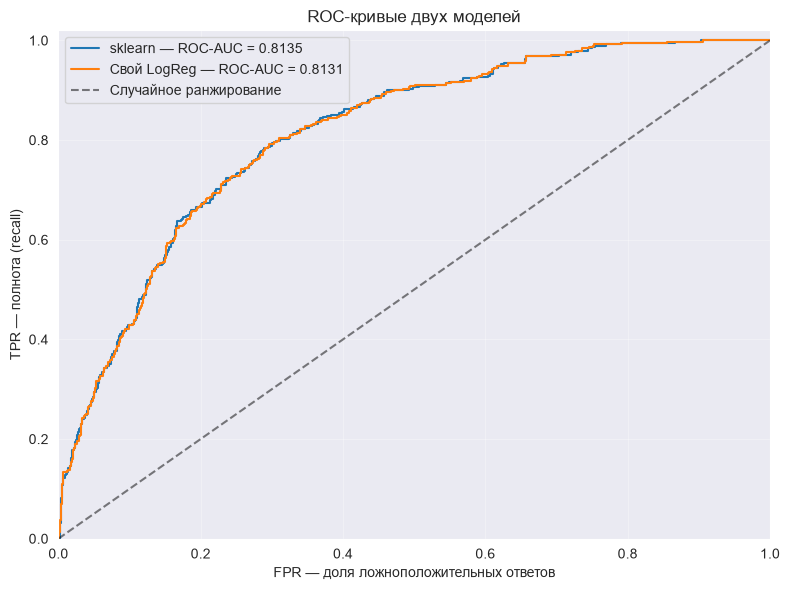

In [31]:
# этот код был написан с помощью ChatGPT-6.1 Sol
plt.figure(figsize=(8, 6))

plt.plot(
    fpr_sklearn, tpr_sklearn,
    label=f'sklearn — ROC-AUC = {roc_auc_sklearn:.4f}'
)
plt.plot(
    fpr_custom, tpr_custom,
    label=f'Свой LogReg — ROC-AUC = {roc_auc_custom:.4f}'
)

plt.plot(
    [0, 1], [0, 1],
    'k--', alpha=0.5,
    label='Случайное ранжирование'
)

plt.xlabel('FPR — доля ложноположительных ответов')
plt.ylabel('TPR — полнота (recall)')
plt.title('ROC-кривые двух моделей')
plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [32]:
from sklearn.metrics import precision_recall_curve

presision_curve_sklearn, recall_curve_sklearn, thresholds_pr_sklearn = precision_recall_curve(y_test, p_sklearn)
presision_curve_custom, recall_curve_custom, thresholds_pr_custom = precision_recall_curve(y_test, p_custom)

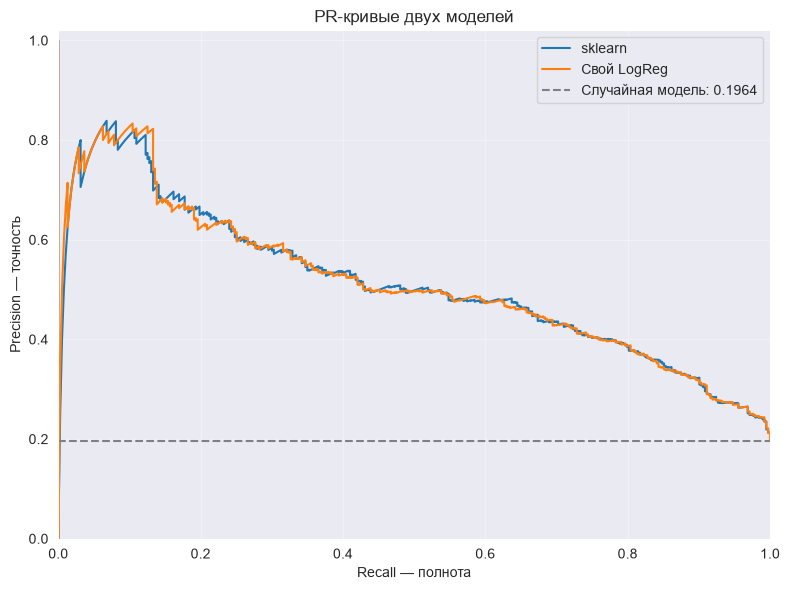

In [33]:
# этот код был написан с помощью ChatGPT-6.1 Sol

baseline = y_test.mean()

plt.figure(figsize=(8, 6))

plt.plot(
    recall_curve_sklearn, presision_curve_sklearn,
    label='sklearn'
)
plt.plot(
    recall_curve_custom, presision_curve_custom,
    label='Свой LogReg'
)

plt.axhline(
    baseline, color='gray', linestyle='--',
    label=f'Случайная модель: {baseline:.4f}'
)

plt.xlabel('Recall — полнота')
plt.ylabel('Precision — точность')
plt.title('PR-кривые двух моделей')
plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [34]:
from sklearn.metrics import average_precision_score

average_precision_sklearn = average_precision_score(y_test, p_sklearn)
average_precision_custom = average_precision_score(y_test, p_custom)

df_ap = pd.DataFrame({
    'Model': ['sklearn', 'Свой LogReg'],
    'ROC-AUC': [roc_auc_sklearn, roc_auc_custom],
    'PR-AUC': [average_precision_sklearn, average_precision_custom]
})

display(df_ap)

,Model,ROC-AUC,PR-AUC
0,sklearn,0.813537,0.512115
1,Свой LogReg,0.813107,0.512495


In [35]:
p_sklearn_10 = p_sklearn * 10
roc_auc_sklearn_10 = roc_auc_score(y_test, p_sklearn_10)

p_sklearn_cube = p_sklearn ** 3
roc_auc_sklearn_cube = roc_auc_score(y_test, p_sklearn_cube)

p_sklearn_log = np.log(p_sklearn / (1 - p_sklearn))
roc_auc_sklearn_log = roc_auc_score(y_test, p_sklearn_log)

p_sklearn_neg = -p_sklearn
roc_auc_sklearn_neg = roc_auc_score(y_test, p_sklearn_neg)

print(f'ROC-AUC for sklearn probabilities: {roc_auc_sklearn:.4f}')
print(f'ROC-AUC for sklearn probabilities * 10: {roc_auc_sklearn_10:.4f}')
print(f'ROC-AUC for sklearn probabilities ** 3: {roc_auc_sklearn_cube:.4f}')
print(f'ROC-AUC for logit of sklearn probabilities: {roc_auc_sklearn_log:.4f}')
print(f'ROC-AUC for negative sklearn probabilities: {roc_auc_sklearn_neg:.4f}')

ROC-AUC for sklearn probabilities: 0.8135
ROC-AUC for sklearn probabilities * 10: 0.8135
ROC-AUC for sklearn probabilities ** 3: 0.8135
ROC-AUC for logit of sklearn probabilities: 0.8135
ROC-AUC for negative sklearn probabilities: 0.1865


In [36]:
labels_sklearn = model_sklearn.predict(X_test)
roc_auc_labels = roc_auc_score(y_test, labels_sklearn)

print(f'ROC-AUC по вероятностям: {roc_auc_sklearn:.4f}')
print(f'ROC-AUC по меткам классов: {roc_auc_labels:.4f}')

ROC-AUC по вероятностям: 0.8135
ROC-AUC по меткам классов: 0.6069


*Ваши выводы здесь.*

- Возьмите вероятности $p$ класса 1 модели из `sklearn` и посчитайте ROC-AUC для преобразованных оценок: $10 \cdot p$, $p^3$, $\log\frac{p}{1-p}$, $-p$. Объясните результат.

ROC-AUC зависит от порядка предсказанных вероятностей, а не от самих значений, поэтому 10 * p, p ** 3 и log(p / (1 - p)) - строго возрастающие преобразования вероятностей сохраняют значение ROC-AUC а -p переворачивает порядок и получается ROC-AUC = 1 - 0.8135 = 0.1865

- Какая модель лучше? Совпадает ли ранжирование моделей по ROC-AUC и по PR-AUC?

По ROC-AUC модель sklearn чуть лучше, а по PR-AUC самописная модель чуть лучше, так что ранжирование не совпадает но нельзя явно назвать какую то модель лучшей

- Чему равен PR-AUC случайной модели в этой задаче и почему он не равен 0.5?

При случайном выборе вин доля хороших среди выбранных в среднем равна доле хороших во всей тестовой выборке (как раз примерно 20%)

- Что получится, если подать в `roc_auc_score` предсказанные метки классов?

При передаче меток ROC-AUC получился примерно 0.6 (при том что по вероятностям примерно 0.8), видимо потому что мы теряем порядок обьектов 


### Задание 2.5. Выбор порога (0.75 балла)

Порог 0.5 у логистической регрессии ничем не выделен – его можно и нужно выбирать под задачу. Но подбирать порог на тестовой выборке нельзя: тогда оценка качества на тесте окажется завышенной.

1. Выделите из тренировочной выборки валидационную (`test_size=0.25`, `stratify`, `random_state=42`). Обучите пайплайн логистической регрессии на оставшейся части и получите вероятности на валидации.
2. Постройте на одном графике зависимость precision, recall и $F_1$ на валидации от порога $t \in [0, 1]$.
3. По валидации выберите два порога:
   - $t_{F_1}$ – максимизирующий $F_1$;
   - $t_{R}$ – дающий максимальный precision при условии recall $\ge 0.7$ (сервис хочет, чтобы в подборку попадало не меньше 70% хороших вин).
4. Переобучите пайплайн на всей тренировочной выборке и посчитайте на тестовой выборке precision, recall и $F_1$ при порогах $0.5$, $t_{F_1}$ и $t_{R}$. Сведите результаты в таблицу.

Выполнилось ли на тесте условие recall $\ge 0.7$? Почему порог, подобранный на валидации, не гарантирует выполнения условия на новых данных? Какой порог вы бы выбрали для сценария из описания данных и почему?

In [37]:
X_train_part, X_val, y_train_part, y_val = train_test_split(X_train, y_train, test_size=0.25, stratify=y_train, random_state=42)

print('Обучение:', X_train_part.shape, y_train_part.shape)
print('Валидация:', X_val.shape, y_val.shape)

Обучение: (3410, 12) (3410,)
Валидация: (1137, 12) (1137,)


In [38]:
pipeline_val = make_pipeline(
    StandardScaler(),
    LogisticRegression()
)

model_val = pipeline_val
model_val.fit(X_train_part, y_train_part)

prediction_val = model_val.predict_proba(X_val)

p_val = prediction_val[:, -1]

p_val.shape

(1137,)

In [39]:
t = 0.5
y_val_pred = (p_val >= t).astype(int)

precision_val = metrics.precision_score(y_val, y_val_pred, zero_division=0)
recall_val = metrics.recall_score(y_val, y_val_pred, zero_division=0)
f1_val = metrics.f1_score(y_val, y_val_pred, zero_division=0)

print(f'Precision: {precision_val:.4f}')
print(f'Recall: {recall_val:.4f}')
print(f'F1: {f1_val:.4f}')

Precision: 0.5941
Recall: 0.2679
F1: 0.3692


In [40]:
thresholds = np.unique(np.append(p_val, [0, 1]))
precision_values, recall_values, f1_values = [], [], []

for threshold in thresholds:
    y_val_pred = (p_val >= threshold).astype(int)

    precision_val = metrics.precision_score(y_val, y_val_pred, zero_division=0)
    recall_val = metrics.recall_score(y_val, y_val_pred, zero_division=0)
    f1_val = metrics.f1_score(y_val, y_val_pred, zero_division=0)

    precision_values.append(precision_val)
    recall_values.append(recall_val)
    f1_values.append(f1_val)
    

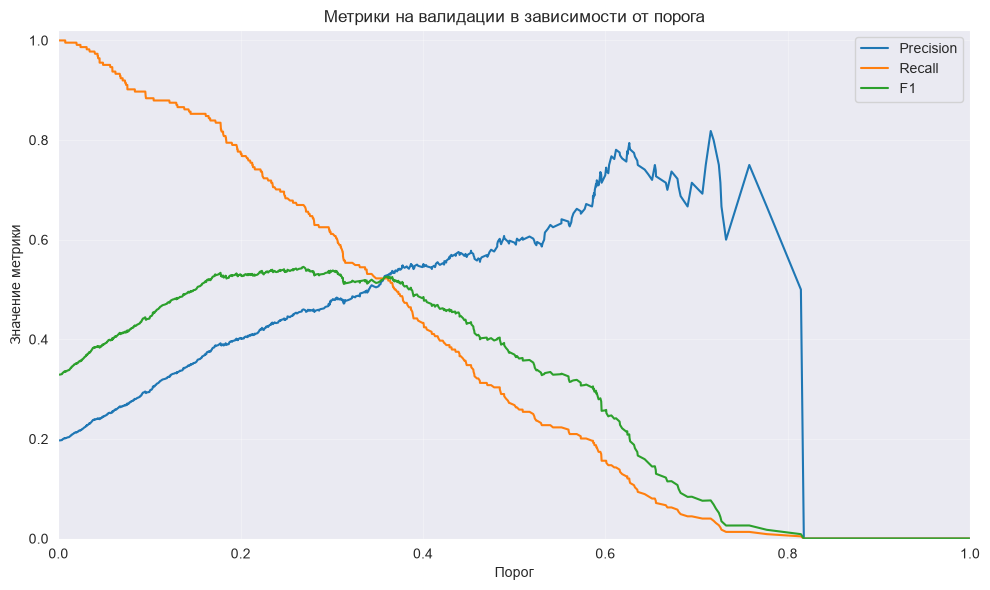

In [41]:
# этот код был написан с помощью ChatGPT-6.1 Sol

plt.figure(figsize=(10, 6))

plt.plot(thresholds, precision_values, label='Precision')
plt.plot(thresholds, recall_values, label='Recall')
plt.plot(thresholds, f1_values, label='F1')

plt.xlabel('Порог')
plt.ylabel('Значение метрики')
plt.title('Метрики на валидации в зависимости от порога')
plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [42]:
max_f1 = np.argmax(f1_values)
t_f1 = thresholds[max_f1]

print(t_f1)

0.26888872700642624


In [43]:
precision_array = np.array(precision_values)
recall_array = np.array(recall_values)

mask = recall_array >= 0.7

valid_thresholds = thresholds[mask]
valid_precision = precision_array[mask]
valid_recall = recall_array[mask]

best_r_idx = np.argmax(valid_precision)
t_R = valid_thresholds[best_r_idx]

print(f'Порог t_R: {t_R:.4f}')
print(f'Precision: {valid_precision[best_r_idx]:.4f}')
print(f'Recall: {valid_recall[best_r_idx]:.4f}')

Порог t_R: 0.2432
Precision: 0.4385
Recall: 0.7009


In [44]:
pipeline_final = make_pipeline(
    StandardScaler(),
    LogisticRegression()
)

pipeline_final.fit(X_train, y_train)

prediction_final = pipeline_final.predict_proba(X_test)
p_test = prediction_final[:, 1]


In [45]:
# этот код был написан с помощью ChatGPT-6.1 Sol (я уже поплыл сорян)


test_thresholds = {
    'Стандартный': 0.5,
    'Максимум F1': t_f1,
    'Recall ≥ 0.7 на валидации': t_R
}

test_results = []

for name, threshold in test_thresholds.items():
    y_test_pred = (p_test >= threshold).astype(int)

    test_results.append({
        'Вариант': name,
        'Порог': threshold,
        'Precision': metrics.precision_score(
            y_test, y_test_pred, zero_division=0
        ),
        'Recall': metrics.recall_score(
            y_test, y_test_pred, zero_division=0
        ),
        'F1': metrics.f1_score(
            y_test, y_test_pred, zero_division=0
        )
    })

df_thresholds = pd.DataFrame(test_results)
display(df_thresholds.round(4))

,Вариант,Порог,Precision,Recall,F1
0,Стандартный,0.5000,0.5976,0.2559,0.3583
1,Максимум F1,0.2689,0.4739,0.6397,0.5444
2,Recall ≥ 0.7 на валидации,0.2432,0.4370,0.6789,0.5317


*Ваши выводы здесь.*

Выполнилось ли на тесте условие recall $\ge 0.7$? Почему порог, подобранный на валидации, не гарантирует выполнения условия на новых данных? Какой порог вы бы выбрали для сценария из описания данных и почему?

Нет не выполнилось (при t_R =  0.2432 получили recall =  0.6789).

Потому что валидационная и тестовая выборки содержат разне обьекты и метрики отличаются. 

Я бы выбрал t_R (примерно 0.24) так как при таком пороге мы находим примерно 68% хороших вин (вместо 26 при пороге 0.5), жертвуя тем что в подборку попдает больше посредственных (примерно на 16 процентных пунктов больше).

## <font color="green">Часть 3. Несбалансированные классы (2.5 балла)</font>

Класс «хорошее вино» встречается примерно в 5 раз реже остальных. На семинаре 4 мы обсуждали, что с этим можно сделать:
- задать классам веса (`class_weight='balanced'`);
- сбалансировать обучающую выборку: undersampling, oversampling и их комбинации (библиотека [imbalanced-learn](https://imbalanced-learn.org/stable/)).

Во всех заданиях этой части сравнивайте модели по одному и тому же набору метрик на тестовой выборке: accuracy, precision, recall, $F_1$ (при пороге по умолчанию), ROC-AUC и PR-AUC. Удобно написать для этого одну функцию, которая принимает обученную модель и возвращает строку таблицы.

**Важно:** ресемплинг применяется **только к тренировочной выборке**. Тестовая выборка остаётся нетронутой, иначе метрики перестанут отражать качество на реальном распределении классов.

In [46]:
from sklearn.metrics import f1_score, recall_score

def evaluate_model(model, X, y, name, threshold=0.5):
    p = model.predict_proba(X)[:, 1]
    y_pred = (p >= threshold).astype(int)
    accuracy = accuracy_score(y, y_pred)
    precision = precision_score(y, y_pred, zero_division=0)
    recall = recall_score(y, y_pred, zero_division=0)
    f1 = f1_score(y, y_pred, zero_division=0)
    roc = roc_auc_score(y, p)
    pr = average_precision_score(y, p)

    return {
        'Model': name,
        'Threshold': threshold,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1': f1,
        'ROC-AUC': roc,
        'PR-AUC': pr
    }

### Задание 3.1. Веса классов (0.5 балла)

Обучите логистическую регрессию в пайплайне со `StandardScaler` с параметром `class_weight=None` и `class_weight='balanced'`. Сведите метрики двух моделей в таблицу.

1. Какие веса получают объекты классов 0 и 1 при `class_weight='balanced'`? Посчитайте их по формуле из документации `sklearn`.
2. Какие метрики заметно изменились, а какие почти нет? Объясните, почему.

In [47]:
pipeline_none = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight=None)
)

pipeline_balanced = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight='balanced')
)

model_none = pipeline_none
model_balanced = pipeline_balanced

model_none.fit(X_train, y_train)
model_balanced.fit(X_train, y_train)

none = evaluate_model(model_none, X_test, y_test, 'none')
balanced = evaluate_model(model_balanced, X_test, y_test, 'balanced')

res = pd.DataFrame([none, balanced])
res

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,none,0.5,0.820000,0.597561,0.255875,0.358318,0.813537,0.512115
1,balanced,0.5,0.726667,0.396978,0.754569,0.520252,0.811339,0.500536


In [48]:
weights = len(y_train) / (y_train.value_counts() * 2)
print(weights)

target
0    0.622365
1    2.543065
Name: count, dtype: float64


*Ваши выводы здесь.*
1. Какие веса получают объекты классов 0 и 1 при `class_weight='balanced'`? Посчитайте их по формуле из документации `sklearn`.

0    0.622365

1    2.543065

2. Какие метрики заметно изменились, а какие почти нет? Объясните, почему.

recall и f1 заметно выросли, precision и accuracy снизились, ROC-AUC почти не изменился, PR-Auc немного снизился
Пропускать хорошие вина при обучении стало дороже так что модель чаще относит вина к первому классу

### Задание 3.2. Ресемплинг (1 балл)

С помощью `imblearn.pipeline.make_pipeline` соберите пайплайны логистической регрессии с разными способами балансировки:
- `RandomUnderSampler`;
- `NearMiss(version=2)`;
- `RandomOverSampler`;
- `SMOTE`.

Для каждого метода выведите размеры классов в обучающей выборке после ресемплинга и добавьте строку в таблицу метрик из задания 3.1.

Ответьте на вопросы:
- Почему здесь нужен `make_pipeline` именно из `imblearn`, а не из `sklearn`? Что произойдёт с тестовой выборкой при вызове `predict` у такого пайплайна?
- Почему нельзя сначала сбалансировать весь датасет, а уже потом разбить его на train и test?
- Какой из методов оказался лучшим по PR-AUC, а какой – худшим? Как вы думаете, почему?
- Для каких из четырёх методов важен порядок шагов «ресемплинг» и «масштабирование» в пайплайне, а для каких нет? Почему? Проверьте на одном из методов, что изменится, если поменять шаги местами.

In [49]:
from imblearn.pipeline import make_pipeline as make_imblearn_pipeline
from imblearn.under_sampling import RandomUnderSampler

model_under = make_imblearn_pipeline(
    StandardScaler(),
    RandomUnderSampler(random_state=42),
    LogisticRegression()
)
model_under.fit(X_train, y_train)

under = evaluate_model(
    model_under, X_test, y_test, 'RandomUnderSampler'
)

res = pd.DataFrame([none, balanced, under])
res


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,none,0.5,0.820000,0.597561,0.255875,0.358318,0.813537,0.512115
1,balanced,0.5,0.726667,0.396978,0.754569,0.520252,0.811339,0.500536
2,RandomUnderSampler,0.5,0.729744,0.401099,0.762402,0.525653,0.809354,0.500791


In [50]:
indices = model_under[1].sample_indices_
print(y_train.iloc[indices].value_counts())

target
0    894
1    894
Name: count, dtype: int64


In [51]:
from imblearn.under_sampling import NearMiss

model_nearmiss = make_imblearn_pipeline(
    StandardScaler(),
    NearMiss(version=2),
    LogisticRegression()
)

model_nearmiss.fit(X_train, y_train)

nearmiss = evaluate_model(
    model_nearmiss, X_test, y_test, 'NearMiss'
)

res = pd.DataFrame([none, balanced, under, nearmiss])
res

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,none,0.5,0.820000,0.597561,0.255875,0.358318,0.813537,0.512115
1,balanced,0.5,0.726667,0.396978,0.754569,0.520252,0.811339,0.500536
2,RandomUnderSampler,0.5,0.729744,0.401099,0.762402,0.525653,0.809354,0.500791
3,NearMiss,0.5,0.544103,0.281897,0.853786,0.423850,0.739948,0.400108


In [52]:
indices = model_nearmiss[1].sample_indices_
print(y_train.iloc[indices].value_counts())

target
0    894
1    894
Name: count, dtype: int64


In [53]:
from imblearn.over_sampling import RandomOverSampler

model_over = make_imblearn_pipeline(
    StandardScaler(),
    RandomOverSampler(random_state=42),
    LogisticRegression()
)
model_over.fit(X_train, y_train)

over = evaluate_model(
    model_over, X_test, y_test, 'Over'
)

res = pd.DataFrame([none, balanced, under, nearmiss, over])
res

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,none,0.5,0.820000,0.597561,0.255875,0.358318,0.813537,0.512115
1,balanced,0.5,0.726667,0.396978,0.754569,0.520252,0.811339,0.500536
2,RandomUnderSampler,0.5,0.729744,0.401099,0.762402,0.525653,0.809354,0.500791
3,NearMiss,0.5,0.544103,0.281897,0.853786,0.423850,0.739948,0.400108
4,Over,0.5,0.726667,0.397260,0.757180,0.521114,0.811484,0.500225


In [54]:
indices = model_over[1].sample_indices_
print(y_train.iloc[indices].value_counts())

target
0    3653
1    3653
Name: count, dtype: int64


In [55]:
from imblearn.over_sampling import SMOTE

model_smote = make_imblearn_pipeline(
    StandardScaler(),
    SMOTE(random_state=42),
    LogisticRegression()
)
model_smote.fit(X_train, y_train)

smote = evaluate_model(
    model_smote, X_test, y_test, 'SMOTE'
)

res = pd.DataFrame([none, balanced, under, nearmiss, over, smote])
res

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,none,0.5,0.820000,0.597561,0.255875,0.358318,0.813537,0.512115
1,balanced,0.5,0.726667,0.396978,0.754569,0.520252,0.811339,0.500536
2,RandomUnderSampler,0.5,0.729744,0.401099,0.762402,0.525653,0.809354,0.500791
3,NearMiss,0.5,0.544103,0.281897,0.853786,0.423850,0.739948,0.400108
4,Over,0.5,0.726667,0.397260,0.757180,0.521114,0.811484,0.500225
5,SMOTE,0.5,0.729231,0.399166,0.749347,0.520871,0.812465,0.503985


In [56]:
# этот код был написан с помощью ChatGPT-6.1 Sol 

smote_counts = y_train.value_counts().copy()

for label, added_count in model_smote[1].sampling_strategy_.items():
    smote_counts.loc[label] += added_count

print(smote_counts)

target
0    3653
1    3653
Name: count, dtype: int64


In [57]:
model_nearmiss_reverse = make_imblearn_pipeline(
    NearMiss(version=2),
    StandardScaler(),
    LogisticRegression()
)
model_nearmiss_reverse.fit(X_train, y_train)

nearmiss_reverse = evaluate_model(model_nearmiss_reverse, X_test, y_test, 'NearMiss reverse')

res = pd.DataFrame([none, balanced, under, nearmiss, over, smote, nearmiss_reverse])
res

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,none,0.5,0.820000,0.597561,0.255875,0.358318,0.813537,0.512115
1,balanced,0.5,0.726667,0.396978,0.754569,0.520252,0.811339,0.500536
2,RandomUnderSampler,0.5,0.729744,0.401099,0.762402,0.525653,0.809354,0.500791
3,NearMiss,0.5,0.544103,0.281897,0.853786,0.423850,0.739948,0.400108
4,Over,0.5,0.726667,0.397260,0.757180,0.521114,0.811484,0.500225
5,SMOTE,0.5,0.729231,0.399166,0.749347,0.520871,0.812465,0.503985
6,NearMiss reverse,0.5,0.681026,0.351183,0.736292,0.475548,0.755049,0.393364


In [58]:
order_comparison = pd.DataFrame([nearmiss, nearmiss_reverse])
order_comparison

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,NearMiss,0.5,0.544103,0.281897,0.853786,0.423850,0.739948,0.400108
1,NearMiss reverse,0.5,0.681026,0.351183,0.736292,0.475548,0.755049,0.393364


*Ваши выводы здесь.*

- Почему здесь нужен `make_pipeline` именно из `imblearn`, а не из `sklearn`? Что произойдёт с тестовой выборкой при вызове `predict` у такого пайплайна?

Потому что при ресемплинге меняется количество обьектов и нам нудно сопоставлять оставленные строки из X_train с y_train. Короче говоря склерновский пайплайн не умеет работать с семплерами которые меняют размер выборки.

При вызове predict тестовая выборка не изменится, так как ресемплинг применяется только во время обучения.

- Почему нельзя сначала сбалансировать весь датасет, а уже потом разбить его на train и test?

Потому что если сначала сбалансировать а потом разбить то может возникнуть ситуация в которой одинаковые обьекты окажутся и в train и в test и произойдет утечка данных (в случае напримр oversampler). Ну и так же тест перестанет отражать реальную долю хороших вин.

- Какой из методов оказался лучшим по PR-AUC, а какой – худшим? Как вы думаете, почему?

Лучший - SMOTE, худший - NearMiss. Скорее всего, SMOTE увеличил за счёт новых примеров хороших вин, а NearMiss при отборе удалил слишком много полезных примеров посредственных вин.

- Для каких из четырёх методов важен порядок шагов «ресемплинг» и «масштабирование» в пайплайне, а для каких нет? Почему? Проверьте на одном из методов, что изменится, если поменять шаги местами.

У NearMiss и SMOTE порядок влияет на сам ресемплинг, потому что они используют расстояния между объектами.

У RandomUnderSampler и RandomOverSampler при одинаковом random_state выбор строк от масштаба признаков не зависит.
Но итоговые метрики могут измениться и у случайных методов, потому что scaler до и после ресемплинга обучается на разных данных.


### Задание 3.3. Веса классов или порог? (0.75 балла)

Сравните на тестовой выборке две модели:
- логистическую регрессию с `class_weight='balanced'` и порогом 0.5;
- логистическую регрессию без весов с порогом $t_{F_1}$ из задания 2.5.

Постройте их PR-кривые на одном графике и отметьте на каждой кривой точку, соответствующую выбранному порогу. Сильно ли различаются кривые? Можно ли сказать, что взвешивание классов в основном «сдвигает порог»?

In [59]:
none_f1 = evaluate_model(
    model_none, X_test, y_test,
    'Без весов, порог t_f1',
    threshold=t_f1
)

comparison = pd.DataFrame([balanced, none_f1])
display(comparison.round(4))

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,balanced,0.5000,0.7267,0.3970,0.7546,0.5203,0.8113,0.5005
1,"Без весов, порог t_f1",0.2689,0.7897,0.4739,0.6397,0.5444,0.8135,0.5121


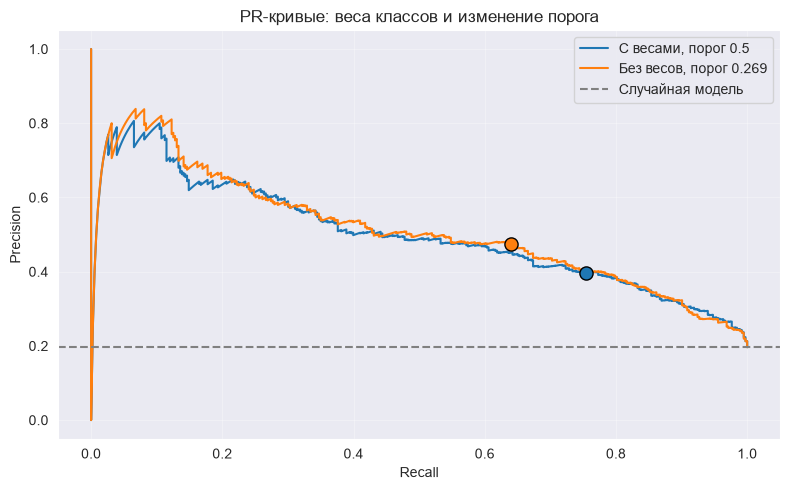

In [60]:
# этот код был написан с помощью ChatGPT-6.1 Sol 

plt.figure(figsize=(8, 5))

for model, result, label, color in [
    (model_balanced, balanced, 'С весами, порог 0.5', 'tab:blue'),
    (model_none, none_f1, f'Без весов, порог {t_f1:.3f}', 'tab:orange')
]:
    p = model.predict_proba(X_test)[:, 1]
    precision, recall, _ = precision_recall_curve(y_test, p)

    plt.plot(recall, precision, label=label, color=color)
    plt.scatter(
        result['Recall'], result['Precision'],
        color=color, s=90, edgecolors='black', zorder=3
    )

plt.axhline(
    np.mean(y_test), color='gray', linestyle='--',
    label='Случайная модель'
)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('PR-кривые: веса классов и изменение порога')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

*Ваши выводы здесь.*

PR-кривые почти совпадают, модели примерно одинаково ранжируют вина. Взвешивание классов в основном действует как снижение порога (модель чаще выбирает хорошие вина, recall растёт, а precision падает). Но полного совпадения нет, поскольку веса меняют и само обучение.

### Задание 3.4. Итоги (0.25 балла)

Сведите в одну таблицу все модели частей 2 и 3 (метрики на тестовой выборке). Какую модель и какой порог вы бы предложили сервису из сценария? Обоснуйте выбор, опираясь на метрики.

In [61]:
custom_result = evaluate_model(
    model_custom, X_test, y_test, 'Свой LogReg'
)

none_recall = evaluate_model(
    model_none, X_test, y_test,
    'Без весов, порог t_R',
    threshold=t_R
)

dummy_result = evaluate_model(
    model_dummy, X_test, y_test, 'Dummy'
)

final_results = pd.DataFrame([
    dummy_result,
    none,
    custom_result,
    none_f1,
    none_recall,
    balanced,
    under,
    nearmiss,
    over,
    smote,
    nearmiss_reverse
])

display(final_results.round(4))

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Dummy,0.5000,0.8036,0.0000,0.0000,0.0000,0.5000,0.1964
1,none,0.5000,0.8200,0.5976,0.2559,0.3583,0.8135,0.5121
2,Свой LogReg,0.5000,0.8195,0.5963,0.2507,0.3529,0.8131,0.5125
3,"Без весов, порог t_f1",0.2689,0.7897,0.4739,0.6397,0.5444,0.8135,0.5121
4,"Без весов, порог t_R",0.2432,0.7651,0.4370,0.6789,0.5317,0.8135,0.5121
5,balanced,0.5000,0.7267,0.3970,0.7546,0.5203,0.8113,0.5005
6,RandomUnderSampler,0.5000,0.7297,0.4011,0.7624,0.5257,0.8094,0.5008
7,NearMiss,0.5000,0.5441,0.2819,0.8538,0.4238,0.7399,0.4001
8,Over,0.5000,0.7267,0.3973,0.7572,0.5211,0.8115,0.5002
9,SMOTE,0.5000,0.7292,0.3992,0.7493,0.5209,0.8125,0.5040


*Ваши выводы здесь.*

Я бы выбрал модель с balanced и порогом 0.5 т.к. она находит около 75% хороших вин. RandomUnderSampler даёт немного лучшие показатели, но разница небольшая, а balanced использует всю обучающую выборку. При этом около 60% рекомендаций остаются ошибочными.

### Сохранение модели (0 баллов, нужно для части 4)

Сохраните итоговую модель (весь пайплайн, а не только `LogisticRegression`), выбранный порог и тестовую выборку – они понадобятся в приложении. Допишите ячейку под свою итоговую модель.

Если работаете в Colab, скачайте папку `wine_app/` на свой компьютер (например, заархивируйте её и воспользуйтесь `google.colab.files.download`): приложение запускается локально.

In [62]:
import json
import joblib
from pathlib import Path

app_dir = Path('wine_app')
app_dir.mkdir(exist_ok=True)

final_model = model_balanced      # ваш итоговый пайплайн, обученный на X_train
final_threshold = 0.5  # выбранный порог

joblib.dump(final_model, app_dir / 'model.joblib')
(app_dir / 'config.json').write_text(json.dumps({'threshold': float(final_threshold)}))
X_test.assign(target=y_test).to_csv(app_dir / 'test.csv', index=False)

## <font color="green">Часть 4. Демо-приложение на Streamlit (2.5 балла)</font>

Модель в ноутбуке видите только вы. Чтобы ей мог пользоваться сомелье сервиса (и чтобы он понимал, почему меняется подборка при изменении порога), сделаем небольшое веб-приложение.

[Streamlit](https://docs.streamlit.io/) это библиотека, которая которая превращает обычный Python-скрипт в веб-страницу: каждый вызов вроде `st.slider(...)` или `st.write(...)` рисует элемент интерфейса, а при любом действии пользователя скрипт перезапускается сверху вниз. Минимальный пример:

```python
import streamlit as st

t = st.slider('Порог', 0.0, 1.0, 0.5)
st.write('Вы выбрали порог', t)
```

Приложение запускается **локально**, а не в Colab:

```bash
pip install streamlit
streamlit run app.py
```

Полезные элементы: [`st.number_input`](https://docs.streamlit.io/develop/api-reference/widgets/st.number_input), [`st.slider`](https://docs.streamlit.io/develop/api-reference/widgets/st.slider), [`st.tabs`](https://docs.streamlit.io/develop/api-reference/layout/st.tabs), [`st.file_uploader`](https://docs.streamlit.io/develop/api-reference/widgets/st.file_uploader), [`st.download_button`](https://docs.streamlit.io/develop/api-reference/widgets/st.download_button), [`st.pyplot`](https://docs.streamlit.io/develop/api-reference/charts/st.pyplot), [`st.metric`](https://docs.streamlit.io/develop/api-reference/data/st.metric), [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource) (чтобы не загружать модель заново при каждом перезапуске скрипта).

Приложение `wine_app/app.py` использует файлы, сохранённые в ячейке выше (`model.joblib`, `config.json`, `test.csv`). **Модель внутри приложения не обучается.**

### Задание 4.1. Оценка одного вина (0.5 балла)

Сделайте вкладку, на которой пользователь вводит 12 признаков вина (диапазоны и значения по умолчанию возьмите из данных, например минимум, максимум и медиану по `test.csv`; признак `is_red` – переключатель «красное / белое»). Сделайте сайдбар с интерактивным ползунком значения порога, установите порог по умолчанию значением из файла `config.json`. Приложение показывает вероятность того, что вино хорошее, и решение модели при установленном пороге.

### Задание 4.2. Интерактивная визуализация модельных метрик (0.5 балла)

Сделайте вкладку «Модельные метрики». При изменении порога на тестовой выборке пересчитываются и выводятся:
- матрица ошибок;
- precision, recall и $F_1$;
- ROC- и PR-кривые, на которых отмечена точка, соответствующая текущему порогу.

Добавьте короткий текст для сомелье: что произойдёт с подборкой, если порог увеличить или уменьшить.

### Задание 4.3. Пакетное предсказание (0.5 балла)

Сделайте вкладку, на которой пользователь загружает CSV-файл с признаками вин (без столбца `target`), а приложение показывает таблицу с вероятностью и решением для каждого вина и даёт скачать её через `st.download_button`. Порог для этой вкладки берётся из слайдера задания 4.2 (подсказка: [`st.session_state`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.session_state)) или задаётся отдельно – на ваш выбор.

Приложение не должно падать, если в файле не хватает столбцов: в этом случае выведите понятное сообщение об ошибке (`st.error`).

### Задание 4.4. Что выучила модель (0.25 балла)

Сделайте вкладку с горизонтальной столбчатой диаграммой коэффициентов логистической регрессии (после масштабирования признаков), отсортированных по значению. Подпишите, какие признаки сильнее всего «голосуют» за хорошее вино, а какие – против.

### Задание 4.5. Кэширование (0.25 балла)

Streamlit выполняет `app.py` заново при каждом действии пользователя: сдвинули слайдер порога – скрипт отработал сверху вниз ещё раз. Без кэширования при каждом движении слайдера модель снова читается с диска, а вероятности на тестовой выборке пересчитываются, хотя от порога они не зависят.

1. Модель загружается функцией с декоратором [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource): один объект на весь сервер. Путь к файлу строится от папки, где лежит `app.py` (`Path(__file__).parent`), а не от текущей директории.
2. `test.csv` читается функцией с декоратором [`st.cache_data`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_data).
3. Вероятности класса 1 на тестовой выборке считаются один раз, в функции с `st.cache_data`. При движении слайдера в задании 4.2 меняется только сравнение с порогом, `predict_proba` заново не вызывается. Подсказка: аргумент, который Streamlit не должен хешировать (например, модель), называют с подчёркиванием в начале: `def test_proba(_model, X): ...`.

Ответьте в `README.md` или в комментарии в `app.py`: почему для модели используется `st.cache_resource`, а для таблиц – `st.cache_data`? Что изменится, если вызвать `joblib.load` без декоратора?

Использование `joblib.load` без декоратора или загрузка модели через `st.cache_data` за этот пункт не засчитываются.

### Задание 4.6. Оформление и сдача (0.5 балла)

1. Сдайте папку `wine_app/` (архивом или укажите в клетке ниже ссылку на Github репозиторий) со следующим содержимым:
- `app.py`;
- `model.joblib`, `config.json`, `test.csv`;
- `requirements.txt` с версиями библиотек, при которых приложение запускается;
- `README.md`: инструкция о том, как запустить приложение с указанием версии Python интерпретатора.

2. Проведите деплой приложения на [Streamlit Community Cloud](https://streamlit.io/cloud).

**Опишите общие мысли о работе. Это место для вашей рефлексии – необязательное, но полезное.** 🍷

я устал босс